
  # Laboratorio 1 — Implementando un Algoritmo Genético para Optimizar  una Parábola

  **Materia:** Inteligencia Artificial — FP-UNA
  **Profesor:** Christian von Lücken
  **Alumno:** David Gómez

  **Objetivo:** encontrar los parámetros `(a, b, c)` de la parábola `y =
  a·x² + b·x + c`
  que produzcan la curva **más plana posible hacia arriba** (`a > 0`),
  usando un
  algoritmo genético implementado desde cero.

 ## Parte 1 — Lectura y comprensión teórica


 ### 1.1 ¿Qué es un algoritmo genético y en qué se inspira?
 

Un algoritmo genético (GA) es una **metaheurística de búsqueda y optimización, poblacional y estocástica**: resuelve un problema haciendo evolucionar un conjunto de soluciones candidatas, en lugar de construir una única solución paso a paso. Pertenece a la familia de las heurísticas tal como se las definió en clase, o sea técnicas que buscan soluciones buenas(pero que pueden no ser las mejores) a un costo computacional razonable, sin garantizar factibilidad ni optimalidad, pero no pueden dererminar qué tan cerca quedo el resultado del valor optimo. Fue desarrollado por **John H. Holland** a principios de la década de 1960 con el nombre de "planes reproductivos y adaptativos", en un intento por hacer que las computadoras aprendieran imitando el proceso de la evolución.

Su funcionamiento es un ciclo que se repite: se parte de una población inicial de soluciones codificadas, se le asigna a cada una un valor de aptitud (*fitness*) que mide su calidad, y se construye la generación siguiente aplicando selección, cruzamiento y mutación. Al repetir el ciclo, la aptitud de la población tiende a mejorar.

La inspiración es el **neo-darwinismo**, que explica toda la vida en el planeta mediante cuatro procesos: **reproducción, mutación, competencia y selección**. Un algoritmo genético es, literalmente, una simulación computacional de esos cuatro procesos. La referencia de fondo es Darwin (1858): la evolución se origina por cambios aleatorios en características hereditarias combinados con un proceso de selección natural. La distinción con Lamarck es importante y no es un detalle histórico: el individuo no mejora durante su vida para después transmitir esa mejora, sino que la variación aparece **al azar** y es la selección la que la filtra. Por eso en un GA la mutación es ciega al objetivo y toda la presión hacia la mejora la ejerce la selección.

De la biología se toma también el vocabulario: el **cromosoma** (o individuo) es una solución candidata codificada; el **gen** es cada una de sus componentes; el **alelo**, el conjunto de valores que un gen puede tomar; el **genotipo** es la solución codificada y el **fenotipo**, la solución ya decodificada en el dominio del problema. En este laboratorio el individuo es la terna `(a, b, c)` con los coeficientes de la parábola.

### 1.2 Población, función de fitness, selección, crossover y mutación

**Población.** Conjunto de soluciones candidatas que el algoritmo mantiene y hace evolucionar en paralelo. Que sean varias a la vez es lo que distingue a un GA de una búsqueda local, y lo que le permite muestrear distintas regiones del espacio al mismo tiempo.
*En este laboratorio:* `population_size` ternas `(a, b, c)` de números reales, generadas al azar con `random.uniform(lower_bound, upper_bound)` dentro del rango `[-50, 50]`. La codificación es directa en punto flotante y no binaria, así que acá el genotipo coincide con el fenotipo.

**Función de fitness (aptitud).** Asigna a cada individuo un número que mide qué tan buena es la solución que representa. Es el único componente que depende del problema: todo el resto del algoritmo es genérico.
*En este laboratorio:* mide qué tan plana es la parábola. Calcula el vértice en `x = -b/(2a)`, evalúa cuánto sube la curva desde el vértice hasta `x = -1` y hasta `x = 1`, suma esas dos subidas (`curviness`) y devuelve el valor **negado**, porque el GA maximiza y lo que se busca es minimizar la curvatura. Si `a <= 0` devuelve `-inf`, descartando de entrada las parábolas que abren hacia abajo. Nótese que `c` no influye en el resultado: desplazar la parábola verticalmente no la hace más ni menos plana.

**Selección.** Decide qué individuos se reproducen, dando más probabilidad a los de mejor aptitud. La intensidad de ese sesgo es la **presión selectiva**: mucha presión acelera la convergencia pero aumenta el riesgo de convergencia prematura; poca presión hace que el algoritmo casi no progrese.
*En este laboratorio:* selección por **torneo de tamaño 3** — se toman tres individuos al azar y pasa el de mejor fitness, repitiendo hasta completar la población. La alternativa clásica es la **ruleta**, donde la probabilidad de ser elegido es proporcional al fitness.

**Crossover (cruzamiento).** Combina el material genético de dos padres para producir hijos. Es el mecanismo de **explotación**: no crea material nuevo, recombina el que ya está presente en la población.
*En este laboratorio:* cruzamiento **aritmético**. Se sortea un `alpha` en `[0, 1)` y los hijos resultan de las combinaciones `alpha·p1 + (1-alpha)·p2` y `alpha·p2 + (1-alpha)·p1`. Cada hijo cae sobre el segmento que une a los dos padres, lo que explica por qué la población tiende a contraerse si no interviene la mutación.

**Mutación.** Altera genes al azar con cierta probabilidad. Es el mecanismo de **exploración** o diversificación: es la única fuente de material genético verdaderamente nuevo y, por lo tanto, lo único capaz de sacar a la población de una región donde quedó estancada.
*En este laboratorio:* cada gen se modifica con probabilidad `mutation_rate` sumándole un valor uniforme en `[-1, 1]`, y a continuación se lo recorta para que no se salga de `[lower_bound, upper_bound]`.

A estos cinco componentes el código del tutorial le agrega **elitismo**: el mejor individuo de cada generación se copia sin modificaciones a la generación siguiente, de manera que la mejor solución encontrada nunca se pierde.

### 1.3 ¿Por qué se usa un algoritmo genético para resolver problemas de optimización?

Existen técnicas clásicas muy eficaces cuando el problema tiene la estructura adecuada: el método Simplex para optimización lineal, el gradiente conjugado para la no lineal, la programación dinámica o *branch & bound* para construir soluciones parcialmente. Un algoritmo genético no compite con ellas en ese terreno; se recurre a él justamente cuando esas condiciones no se cumplen.

Un problema se vuelve difícil, en el sentido visto en clase, cuando el número de soluciones posibles es tan grande que una búsqueda exhaustiva resulta inviable el caso típico es el problema del viajante, donde con 50 ciudades hay del orden de 10²⁵ recorridos posibles, cuando la función de evaluación es ruidosa o varía con el tiempo, lo que obliga a trabajar con un conjunto de soluciones en lugar de una sola, o cuando las restricciones son tantas que incluso construir una solución factible es complicado.

En esas condiciones un GA aporta tres ventajas concretas:

- **No necesita derivadas** ni que la función objetivo sea continua o diferenciable. Alcanza con poder evaluarla, es decir, sirve para optimización de caja negra.
- **Trabaja con una población**, de modo que muestrea varias regiones del espacio simultáneamente. Eso lo hace menos propenso a quedar atrapado en un óptimo local que una búsqueda que avanza siguiendo una única solución.
- **Es independiente del dominio.** Lo único específico del problema son la codificación y la función de fitness; el resto —selección, cruzamiento, mutación— es idéntico para una parábola que para el problema del viajante.

La contrapartida es que un GA es una heurística: entrega soluciones buenas a un costo computacional razonable, pero no garantiza alcanzar el óptimo global ni permite saber, en general, a qué distancia del óptimo quedó. Este laboratorio lo ilustra con claridad: la curvatura se minimiza cuando `a` tiende a cero por derecha y `b` tiende a cero, es decir sobre el borde de la región factible (`a > 0`), de modo que el algoritmo puede acercarse indefinidamente pero nunca llegar exactamente.

## Parte 2 — Implementación guiada

In [44]:
import random
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable

random.seed(42) # misma semilla para que podamos tener los mismos resultados y evaluar el resultado

In [45]:
def create_initial_population(size, lower_bound, upper_bound):
    population = []
    for _ in range(size):
        individual = (random.uniform(lower_bound, upper_bound), 
                      random.uniform(lower_bound, upper_bound),
                      random.uniform(lower_bound, upper_bound)
                      )
        population.append(individual)
    return population

In [46]:
def fitness_function(params):
    a, b, c = params
    if a <= 0:
        return -float('inf') # penalizamos las parabolas que se abren hacia abajo

    vertexX = -b / (2 * a)
    vertexY = a * vertexX**2 + b *vertexX + c

    yLeft = a * (-1) ** 2 + b * (-1) + c # y en x = -1
    yRight = a * (1) ** 2 + b * (1) + c # y en x = 1

    curviness = abs(yLeft - vertexY) + abs(yRight - vertexY) 
    return -curviness

In [47]:
population = create_initial_population(5, -50, 50)
for ind in population:
    print(ind)

for p in [(0.5, 0, 3), (0.5, 0, -40), (2, 3, 1), (0.1, 0, 0), (5, 0, 0), (-0.5, 0, 3), (0,1, 1)]:
    print(p, "->", fitness_function(p))

(13.942679845788376, -47.498924477733304, -22.497068163088073)
(-27.678926185117724, 23.647121416401234, 17.669948742291126)
(39.217956770484534, -41.30611673705839, -7.807818031472955)
(-47.020278056192964, -28.136202519639664, 0.5355288103362383)
(-47.34640303161364, -30.11623493133515, 14.988443777952327)
(0.5, 0, 3) -> -1.0
(0.5, 0, -40) -> -1.0
(2, 3, 1) -> -6.25
(0.1, 0, 0) -> -0.2
(5, 0, 0) -> -10.0
(-0.5, 0, 3) -> -inf
(0, 1, 1) -> -inf


In [48]:
def selection(population, fitnesses, tournament_size=3):
    selected = []
    for _ in range(len(population)):
        tournament = random.sample(list(zip(population, fitnesses)), tournament_size)
        winner = max(tournament, key=lambda x: x[1] )[0]
        selected.append(winner)
    return selected


In [49]:
selectioned = selection(population, [fitness_function(p) for p in population])
for ind in selectioned:
    print(ind, "->", fitness_function(ind))

(13.942679845788376, -47.498924477733304, -22.497068163088073) -> -108.79332901653116
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366
(-27.678926185117724, 23.647121416401234, 17.669948742291126) -> -inf
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366


In [50]:
def crossover(parent1, parent2): # el cruzamiento
    alpha = random.random()
    child1 = tuple(alpha * p1 + (1 - alpha) * p2 for p1, p2 in zip(parent1, parent2))
    child2 = tuple(alpha * p2 + (1 - alpha) * p1 for p1, p2 in zip(parent1, parent2))
    return child1, child2

def mutation(individual, mutation_rate, lower_bound, upper_bound):
    individual = list(individual)
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            mutation_amount = random.uniform(-1, 1)
            individual[i] += mutation_amount
            individual[i] = max(min(individual[i], upper_bound), lower_bound)
    return tuple(individual)


In [51]:
for parent1, parent2 in zip(selectioned[::2], selectioned[1::2]):
    child1, child2 = crossover(parent1, parent2)
    print("Parents:", parent1, parent2)
    print("Children:", child1, child2)
    print("mutated Children:", mutation(child1, 0.1, -50, 50), mutation(child2, 0.1, -50, 50))
    print()

Parents: (13.942679845788376, -47.498924477733304, -22.497068163088073) (39.217956770484534, -41.30611673705839, -7.807818031472955)
Children: (29.61518903562354, -43.65893346533902, -13.38866518236414) (23.54544758064937, -45.146107749452675, -16.91622101219689)
mutated Children: (29.61518903562354, -43.65893346533902, -13.38866518236414) (23.464297339993056, -45.146107749452675, -16.91622101219689)

Parents: (-27.678926185117724, 23.647121416401234, 17.669948742291126) (39.217956770484534, -41.30611673705839, -7.807818031472955)
Children: (33.946469142751646, -36.187788704728504, -5.800164963103585) (-22.407438557384836, 18.52879338407135, 15.662295673921758)
mutated Children: (33.946469142751646, -36.187788704728504, -5.800164963103585) (-22.407438557384836, 18.52879338407135, 15.984822311057178)



In [52]:
def genetic_algorithm(population_size, lower_bound, upper_bound, generations, mutation_rate):
    population = create_initial_population(population_size, lower_bound, upper_bound)
    
    best_performers = [] # mejor individio por cada gneracion
    all_populations = [] # snapshot de todas las generaciones

    table = PrettyTable()
    table.field_names = ["Generation", "a", "b", "c", "Fitness"]

    for generation in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]

        best_individual = max(population, key=fitness_function)
        best_fitness = fitness_function(best_individual)
        best_performers.append((best_individual, best_fitness))
        all_populations.append(population[:])
        table.add_row([generation + 1, best_individual[0], best_individual[1], best_individual[2], best_fitness])

        population = selection(population, fitnesses)

        next_population = []
        for i in range(0, len(population), 2):
            child1, child2 = crossover(population[i], population[i + 1])
            next_population.append(mutation(child1, mutation_rate, lower_bound, upper_bound))
            next_population.append(mutation(child2, mutation_rate, lower_bound, upper_bound))

        next_population[0] = best_individual
        population = next_population

    print(table)
    return max(population, key=fitness_function), best_performers, all_populations


In [53]:
population_size = 100
lower_bound = -50
upper_bound = 50
generations = 20
mutation_rate = 1

random.seed(42)
best_solution, best_performers, all_populations = genetic_algorithm(
    population_size, lower_bound, upper_bound, generations, mutation_rate
)

print(f"\nMejor solución: a = {best_solution[0]}, b = {best_solution[1]}, c = {best_solution[2]}")


+------------+---------------------+-----------------------+--------------------+----------------------+
| Generation |          a          |           b           |         c          |       Fitness        |
+------------+---------------------+-----------------------+--------------------+----------------------+
|     1      |  7.1043093325284445 |  -2.7328973688205878  | 28.461942429075336 |  -14.73426638666647  |
|     2      |  7.1043093325284445 |  -2.7328973688205878  | 28.461942429075336 |  -14.73426638666647  |
|     3      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     4      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     5      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     6      |  4.474998141528115  |  -4.9923390990109295  | 2.9343608928326255 |  -11.7347404205144   |
|     7      |  4.129848073535627  |   -3.6066400416307

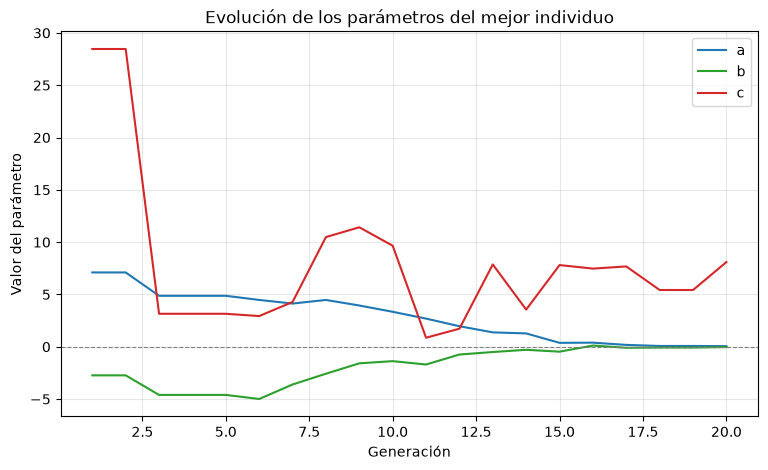

In [54]:
generations_list = list(range(1, len(best_performers) + 1))
a_values = [ind[0][0] for ind in best_performers ]
b_values = [ind[0][1] for ind in best_performers ]
c_values = [ind[0][2] for ind in best_performers ]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(generations_list, a_values, label='a', color='tab:blue')
ax.plot(generations_list, b_values, label='b', color='tab:green')
ax.plot(generations_list, c_values, label='c', color='tab:red')
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Generación')
ax.set_ylabel('Valor del parámetro')
ax.set_title('Evolución de los parámetros del mejor individuo')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

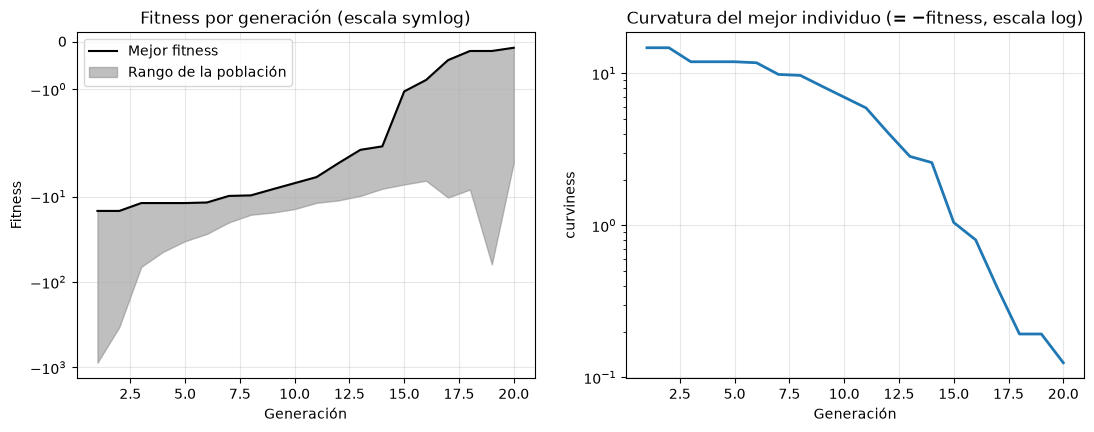

In [55]:
best_fitness_values = [fit[1] for fit in best_performers]

min_fitness_values, max_fitness_values = [], []
for pop in all_populations:
    finites = [f for f in map(fitness_function, pop) if f != -float('inf')]
    min_fitness_values.append(min(finites) if finites else float('nan'))
    max_fitness_values.append(max(finites) if finites else float('nan'))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(generations_list, best_fitness_values, label='Mejor fitness', color='black')
axs[0].fill_between(generations_list, min_fitness_values, max_fitness_values,
                    color='gray', alpha=0.5, label='Rango de la población')
axs[0].set_yscale('symlog')
axs[0].set_xlabel('Generación'); axs[0].set_ylabel('Fitness')
axs[0].set_title('Fitness por generación (escala symlog)')
axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].semilogy(generations_list, [-f for f in best_fitness_values], color='tab:blue', lw=2)
axs[1].set_xlabel('Generación'); axs[1].set_ylabel('curviness')
axs[1].set_title('Curvatura del mejor individuo (= −fitness, escala log)')
axs[1].grid(alpha=0.3)

plt.show()


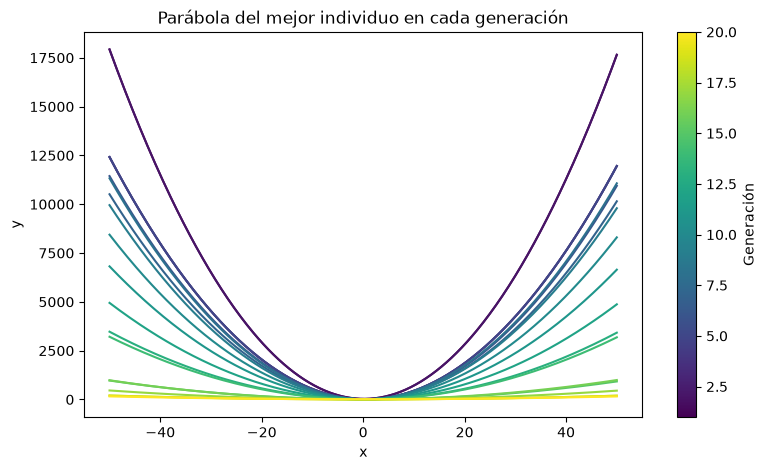

In [56]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = plt.cm.viridis(np.linspace(0, 1, len(best_performers)))
x_range = np.linspace(lower_bound, upper_bound, 400)

for i, (best_ind, best_fit) in enumerate(best_performers):
    a, b, c = best_ind
    ax.plot(x_range, a * x_range**2 + b * x_range + c, color=colors[i])

sm = plt.cm.ScalarMappable(cmap='viridis',
                            norm=plt.Normalize(1, len(best_performers)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label='Generación')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Parábola del mejor individuo en cada generación')
plt.show()

### Pregunta de reflexión

> **¿Qué significa que el algoritmo "encuentre" valores de a ≈ 0 (pero positivo), b ≈ 0 y c cualquiera? ¿Por qué penaliza a ≤ 0 en la función de fitness?**

Las tres observaciones se explican con un único hecho algebraico. La función de fitness evalúa la parábola en el vértice y en `x = ±1`, y suma las dos diferencias en valor absoluto. Al desarrollar esas restas, la expresión se simplifica por completo:

```
vértice:        y_v = c − b²/(4a)

y(−1) − y_v  =  a − b + b²/(4a)  =  (2a − b)² / (4a)
y(+1) − y_v  =  a + b + b²/(4a)  =  (2a + b)² / (4a)

curviness    =  [(2a − b)² + (2a + b)²] / (4a)  =  (8a² + 2b²) / (4a)
```

es decir:

```
curviness = 2·|a| + b²/(2·|a|)            fitness = −curviness
```

Toda la respuesta está contenida en esa expresión.

#### a ≈ 0 pero positivo

Con `b = 0` la curvatura se reduce a `2a`, que decrece de forma monótona a medida que `a` se achica. **No existe un mínimo**: el ínfimo es 0 y no se alcanza, porque `a = 0` está excluido del dominio. Que el algoritmo "encuentre" `a ≈ 0` positivo significa, entonces, que convergió al **borde de la región factible**, y que el óptimo es un límite antes que un punto alcanzable. Geométricamente se le está pidiendo aproximar una parábola degenerada: la curva más plana que abre hacia arriba es, en el límite, una recta horizontal.

Esto tiene una consecuencia práctica comprobable: el algoritmo nunca termina de converger. Repitiendo la misma corrida con más generaciones, `a` sigue bajando indefinidamente (ver la celda siguiente).

#### b ≈ 0

El término `b²/(2·|a|)` penaliza que el vértice esté desplazado respecto de `x = 0`. Con `b ≠ 0` el vértice se ubica en `x = −b/(2a)` y la parábola sube más de un lado que del otro dentro del intervalo `[−1, 1]`, que es justamente donde se mide la planitud.

Dos detalles de ese término importan. `b` entra al cuadrado, así que el castigo es simétrico respecto de su signo; y está **dividido por `a`**, de modo que se vuelve más severo a medida que `a` se achica. La presión selectiva sobre `b` se intensifica sola a lo largo de la corrida. Los resultados lo confirman: a las 50 generaciones el término de `a` aporta el 91 % de la curvatura y el de `b` apenas el 9 %, mientras que a las 200 generaciones la proporción se invierte y `b` pasa a aportar el 64 %. Seguir achicando `a` deja de rendir si `b` no lo acompaña.

#### c cualquiera

`c` no aparece en la expresión: se cancela al restar. No es una casualidad algebraica sino el reflejo de un hecho geométrico — `c` desplaza la parábola entera verticalmente, vértice incluido, y la planitud es una propiedad de la **forma** de la curva, no de su posición.

En términos del algoritmo, el paisaje de fitness es perfectamente **plano** a lo largo del eje `c`, de modo que la selección no ejerce ninguna presión en esa dirección. `c` es un **gen neutro**: su valor final no es producto de la optimización sino del arrastre aleatorio del cruzamiento y la mutación. Cualquier valor de `c` es igualmente óptimo, y eso es exactamente lo que muestra la gráfica de las parábolas: las curvas de las últimas generaciones son todas igual de planas, pero están a distintas alturas.

#### Por qué se penaliza a ≤ 0

Hay dos razones, de naturaleza distinta.

**La primera es de definición.** Con `a = 0` la expresión `x_v = −b/(2a)` divide por cero, y además la función deja de ser una parábola: es una recta. Por eso la guarda es `a <= 0` y no `a < 0`.

**La segunda** Como la función toma valores absolutos, el resultado depende de `|a|` y no de `a`. Una parábola con `a = −0.001` obtiene **exactamente el mismo fitness** que una con `a = +0.001`. Sin la penalización, el algoritmo sería por completo indiferente entre una curva que abre hacia arriba y su reflejo que abre hacia abajo, y aproximadamente la mitad de las soluciones finales quedarían invertidas, lo que no cumple con lo que se dice en el enunciado que la parabola sea plana **hacia arriba**.

La penalización no es una formalidad ni el manejo de un caso de borde: es el único mecanismo que rompe esa simetría y convierte "la parábola más plana" en "la parábola más plana que abre hacia arriba". La forma concreta de implementarla devolver `-inf` es discutible y se retoma en la Parte 4.

#### Evidencia en los resultados obtenidos

| Afirmación | Evidencia en esta corrida |
|---|---|
| `a → 0⁺` | 7.1043 en la generación 1, 0.0592 en la 20 |
| `b → 0` | −2.7329 en la generación 1, −0.0276 en la 20 |
| `c` no converge | 28.46 → 3.15 → 11.42 → 0.87 → 7.87 → 8.10, sin dirección |
| `c` es libre, no indefinido | las curvas finales de la tercera gráfica son planas pero están a distinta altura |
| el óptimo nunca se alcanza | celda siguiente: 20, 50 y 200 generaciones |

In [57]:
# ¿El algoritmo converge a un punto, o se acerca indefinidamente al borde a = 0?
import io, contextlib

for n_gen in (20, 50, 200):
    random.seed(42)
    with contextlib.redirect_stdout(io.StringIO()):      # silencia la tabla de PrettyTable
        _, bp, _ = genetic_algorithm(population_size, lower_bound, upper_bound,
                                     n_gen, mutation_rate)
    ind, fit = bp[-1]
    aporte_a = 2 * abs(ind[0])
    aporte_b = ind[1] ** 2 / (2 * abs(ind[0]))
    total = aporte_a + aporte_b
    print(f"{n_gen:>4} gen -> a = {ind[0]:.8f}   b = {ind[1]:>12.8f}   fitness = {fit:.8f}"
          f"   | curvatura: {aporte_a/total:>4.0%} por a, {aporte_b/total:>4.0%} por b")

  20 gen -> a = 0.05917645   b =  -0.02758193   fitness = -0.12478083   | curvatura:  95% por a,   5% por b
  50 gen -> a = 0.01611702   b =  -0.01017562   fitness = -0.03544627   | curvatura:  91% por a,   9% por b
 200 gen -> a = 0.00623640   b =  -0.01652514   fitness = -0.03436686   | curvatura:  36% por a,  64% por b


---
## Parte 3 — Experimentación y análisis

**Nota metodológica.** Un algoritmo genético es estocástico: la población inicial y los sorteos de
selección, cruzamiento y mutación cambian en cada corrida. Comparar configuraciones con **una sola
ejecución** por configuración no permite distinguir el efecto del parámetro del efecto del azar.
Por eso cada configuración se ejecuta con **10 semillas distintas** (`SEEDS = 1..10`) y se reportan
media, mediana, mejor, peor y desvío estándar.

Salvo lo que cada experimento modifique, la configuración base es la del tutorial:
`population_size = 100`, `lower_bound = -50`, `upper_bound = 50`, `generations = 20`,
`mutation_rate = 1`.

In [58]:
import io, contextlib, statistics

SEEDS = tuple(range(1, 11))     # 10 corridas por configuración


def correr_experimento(**overrides):
    """Corre el GA con varias semillas. Devuelve (curvas_de_fitness, fitness_finales)."""
    params = dict(population_size=100, lower_bound=-50, upper_bound=50,
                  generations=20, mutation_rate=1)
    params.update(overrides)                 # los overrides pisan solo lo que reciben

    curvas = []
    for s in SEEDS:
        random.seed(s)
        with contextlib.redirect_stdout(io.StringIO()):     # silencia la tabla
            _, bp, _ = genetic_algorithm(**params)
        curvas.append([fit for _, fit in bp])
    return curvas, [c[-1] for c in curvas]


def graficar_experimento(resultados, titulo, etiqueta):
    """resultados: lista de (valor_del_parametro, curvas). Grafica la media y la banda min-max."""
    _, ax = plt.subplots(figsize=(9, 5))
    colores = plt.cm.viridis(np.linspace(0, 0.85, len(resultados)))
    for (valor, curvas), color in zip(resultados, colores):
        m = np.array(curvas) * -1                           # curvatura = -fitness (siempre > 0)
        gens = range(1, m.shape[1] + 1)
        ax.plot(gens, m.mean(axis=0), color=color, lw=2, label=f"{etiqueta} = {valor}")
        ax.fill_between(gens, m.min(axis=0), m.max(axis=0), color=color, alpha=0.15)
    ax.set_yscale('log')
    ax.set_xlabel('Generación')
    ax.set_ylabel('Curvatura (= −fitness, escala log)')
    ax.set_title(titulo)
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()

### Experimento 1 — Tamaño de la población

+-----------------+---------------+----------+----------+-----------+---------+--------------+
| population_size | fitness medio | mediana  |  mejor   |    peor   |   desv  | evaluaciones |
+-----------------+---------------+----------+----------+-----------+---------+--------------+
|        50       |    -1.90154   | -0.20756 | -0.02626 | -11.23215 | 3.64030 |     1000     |
|       100       |    -0.15056   | -0.14805 | -0.10423 |  -0.20134 | 0.03542 |     2000     |
|       200       |    -0.07092   | -0.07571 | -0.00846 |  -0.13055 | 0.03434 |     4000     |
+-----------------+---------------+----------+----------+-----------+---------+--------------+


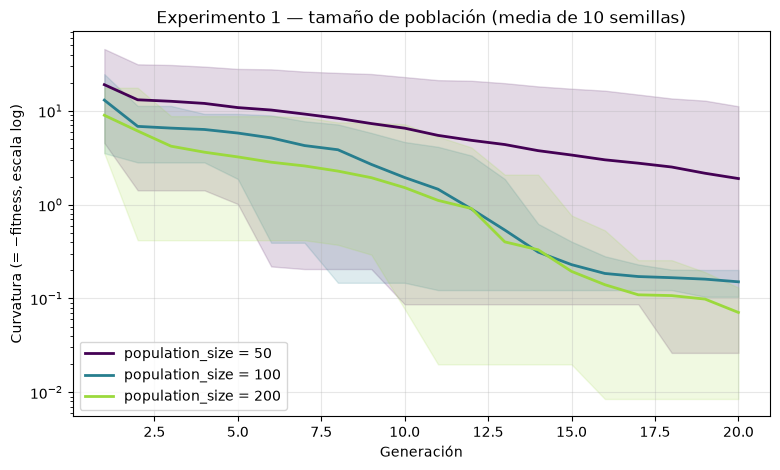

In [59]:
tabla = PrettyTable()
tabla.field_names = ["population_size", "fitness medio", "mediana", "mejor", "peor", "desv", "evaluaciones"]

resultados_1 = []
for n in (50, 100, 200):
    curvas, finales = correr_experimento(population_size=n)
    resultados_1.append((n, curvas))
    tabla.add_row([n,
                   f"{statistics.mean(finales):.5f}",
                   f"{statistics.median(finales):.5f}",
                   f"{max(finales):.5f}",
                   f"{min(finales):.5f}",
                   f"{statistics.pstdev(finales):.5f}",
                   n * 20])
print(tabla)

graficar_experimento(resultados_1,
                     "Experimento 1 — tamaño de población (media de 10 semillas)",
                     "population_size")

#### Control: igualando el presupuesto computacional

La comparación anterior no es justa. Con 200 individuos el algoritmo realiza 4000 evaluaciones de
fitness y con 50 solo 1000: es cuatro veces más cómputo. La comparación correcta mantiene fijo el
**presupuesto** (`population_size × generations = 4000`) y reparte ese presupuesto de distintas maneras.

In [60]:
tabla = PrettyTable()
tabla.field_names = ["population_size", "generations", "evaluaciones", "fitness medio", "mediana", "desv"]
for n, g in ((50, 80), (100, 40), (200, 20), (400, 10)):
    _, finales = correr_experimento(population_size=n, generations=g)
    tabla.add_row([n, g, n * g,
                   f"{statistics.mean(finales):.5f}",
                   f"{statistics.median(finales):.5f}",
                   f"{statistics.pstdev(finales):.5f}"])
print(tabla)

+-----------------+-------------+--------------+---------------+----------+---------+
| population_size | generations | evaluaciones | fitness medio | mediana  |   desv  |
+-----------------+-------------+--------------+---------------+----------+---------+
|        50       |      80     |     4000     |    -0.04651   | -0.05138 | 0.01619 |
|       100       |      40     |     4000     |    -0.05349   | -0.05835 | 0.02490 |
|       200       |      20     |     4000     |    -0.07092   | -0.07571 | 0.03434 |
|       400       |      10     |     4000     |    -1.38926   | -0.79584 | 1.41398 |
+-----------------+-------------+--------------+---------------+----------+---------+


**Análisis del Experimento 1**

Con 20 generaciones fijas, aumentar la población mejora de forma clara tanto la velocidad de
convergencia como la calidad final: el fitness medio pasa de **−1.90** con 50 individuos a **−0.15**
con 100 y **−0.07** con 200. Sin embargo, el efecto más marcado no está en la media sino en la
**dispersión**. Con 50 individuos el desvío es 3.64 y la peor de las diez corridas termina en −11.23;
con 200 el desvío cae a 0.034 y ninguna corrida se despega del resto. La brecha entre la media
(−1.90) y la mediana (−0.21) en el caso de 50 individuos lo confirma: una única corrida catastrófica
arrastra el promedio. Una población chica no es sistemáticamente mala, es **impredecible** — a veces
la población inicial contiene buen material genético y el algoritmo converge bien, y a veces no, y
entonces el cruzamiento no tiene de dónde sacarlo.

La comparación a generaciones fijas, no obstante, es engañosa, porque el costo computacional no es el
mismo. Igualando el presupuesto en 4000 evaluaciones, el orden **se invierte levemente**: −0.047 con
50×80 frente a −0.071 con 200×20, aunque la diferencia es pequeña frente al ruido y no conviene
sobreinterpretarla. El resultado contundente es el caso extremo: con 400 individuos y solo 10
generaciones el fitness medio se desploma a **−1.39**, con un desvío de 1.41. Existe un mínimo de
generaciones por debajo del cual el algoritmo no funciona, por grande que sea la población, porque
acercarse a `a → 0⁺` exige iteraciones sucesivas del "trinquete" de mutación más elitismo, y no más
muestras iniciales. En conclusión, lo que compra el tamaño de la población es **confiabilidad**, no
calidad final por unidad de cómputo.

### Experimento 2 — Tasa de mutación

+---------------+---------------+----------+----------+-----------+---------+
| mutation_rate | fitness medio | mediana  |  mejor   |    peor   |   desv  |
+---------------+---------------+----------+----------+-----------+---------+
|      0.0      |    -7.42169   | -6.75938 | -3.05427 | -12.48632 | 2.94982 |
|      0.1      |    -1.75365   | -1.09730 | -0.14239 |  -7.74245 | 2.17919 |
|      0.5      |    -0.32029   | -0.18149 | -0.06162 |  -1.65282 | 0.45092 |
|      0.8      |    -0.13083   | -0.12651 | -0.03309 |  -0.28805 | 0.07093 |
|      1.0      |    -0.15056   | -0.14805 | -0.10423 |  -0.20134 | 0.03542 |
+---------------+---------------+----------+----------+-----------+---------+


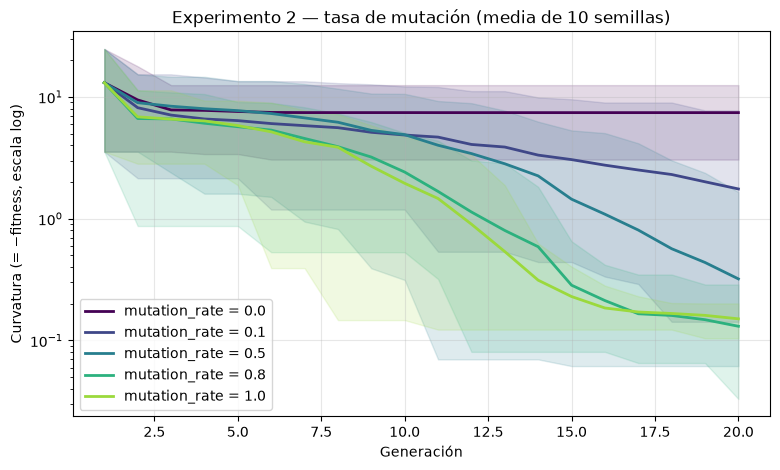

In [61]:
tabla = PrettyTable()
tabla.field_names = ["mutation_rate", "fitness medio", "mediana", "mejor", "peor", "desv"]

resultados_2 = []
for r in (0.0, 0.1, 0.5, 0.8, 1.0):
    curvas, finales = correr_experimento(mutation_rate=r)
    resultados_2.append((r, curvas))
    tabla.add_row([r,
                   f"{statistics.mean(finales):.5f}",
                   f"{statistics.median(finales):.5f}",
                   f"{max(finales):.5f}",
                   f"{min(finales):.5f}",
                   f"{statistics.pstdev(finales):.5f}"])
print(tabla)

graficar_experimento(resultados_2,
                     "Experimento 2 — tasa de mutación (media de 10 semillas)",
                     "mutation_rate")

#### Control: ¿es la tasa, o el tamaño del paso?

El resultado anterior —que más mutación sea mejor— contradice la intuición habitual. La hipótesis es
que no depende de la *tasa* sino del producto de la tasa por la **magnitud del paso**: la mutación de
este código suma `uniform(-1, 1)` sobre un dominio de ancho 100, apenas un 1 % del rango.

Para comprobarlo se repite el barrido de tasas variando el tamaño del paso.

In [62]:
def mutation_con_paso(individual, mutation_rate, lower_bound, upper_bound, paso):
    """Igual que mutation(), pero con el tamaño del paso parametrizado."""
    individual = list(individual)
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] += random.uniform(-paso, paso)
            individual[i] = max(min(individual[i], upper_bound), lower_bound)
    return tuple(individual)


def ga_con_paso(mutation_rate, paso, seed, population_size=100, generations=20,
                lower_bound=-50, upper_bound=50):
    random.seed(seed)
    population = create_initial_population(population_size, lower_bound, upper_bound)
    for _ in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]
        best_individual = max(population, key=fitness_function)
        population = selection(population, fitnesses)
        next_population = []
        for i in range(0, len(population), 2):
            c1, c2 = crossover(population[i], population[i + 1])
            next_population.append(mutation_con_paso(c1, mutation_rate, lower_bound, upper_bound, paso))
            next_population.append(mutation_con_paso(c2, mutation_rate, lower_bound, upper_bound, paso))
        next_population[0] = best_individual
        population = next_population
    return max(fitness_function(ind) for ind in population)


tabla = PrettyTable()
tabla.field_names = ["paso de mutación", "rate = 0.1", "rate = 0.5", "rate = 0.8", "rate = 1.0"]
for paso, etiqueta in ((1, "±1   (1 % del rango)"), (5, "±5   (5 %)"),
                       (25, "±25  (25 %)"), (50, "±50  (50 %)")):
    fila = [etiqueta]
    for r in (0.1, 0.5, 0.8, 1.0):
        valores = [ga_con_paso(r, paso, s) for s in SEEDS]
        fila.append(f"{statistics.mean(valores):.3f}")
    tabla.add_row(fila)
print(tabla)

+----------------------+------------+------------+------------+------------+
|   paso de mutación   | rate = 0.1 | rate = 0.5 | rate = 0.8 | rate = 1.0 |
+----------------------+------------+------------+------------+------------+
| ±1   (1 % del rango) |   -1.625   |   -0.299   |   -0.120   |   -0.134   |
|      ±5   (5 %)      |   -0.437   |   -0.402   |   -0.345   |   -0.365   |
|     ±25  (25 %)      |   -1.453   |   -1.275   |   -2.050   |   -2.090   |
|     ±50  (50 %)      |   -1.841   |   -2.274   |   -2.487   |   -2.721   |
+----------------------+------------+------------+------------+------------+


**Análisis del Experimento 2**

La tasa de mutación resultó el parámetro más determinante de los dos. Con `mutation_rate = 0.0` el
algoritmo queda completamente estancado en **−7.42**, y en la gráfica se ve como una línea horizontal
desde las primeras generaciones. La causa es estructural: el cruzamiento aritmético produce
combinaciones convexas de los padres, de modo que todo hijo cae sobre el segmento que los une y
**nunca puede generar un valor de `a` menor que el más chico presente en la población**. Sin
mutación, el algoritmo no tiene forma de alcanzar el óptimo, que está en el borde `a → 0⁺`. A partir
de ahí el resultado mejora de forma monótona: −1.75 con 0.1, −0.32 con 0.5 y **−0.13 con 0.8**, para
estabilizarse en −0.15 con 1.0.

Lo interesante es que **la "demasiada aleatoriedad" que cabría esperar en el extremo alto no
aparece**. La razón es el tamaño del paso: la mutación suma un valor uniforme en [−1, 1] sobre un
dominio de ancho 100, es decir un 1 % del rango. Aun mutando los tres genes en todas las
generaciones, la perturbación es suave: en esta implementación la mutación no cumple el papel de
diversificación sino el de **búsqueda local**, un paso chico que va empujando `a` hacia el borde
`a → 0⁺` generación tras generación. Como el óptimo está justamente en ese borde y debe alcanzarse
de forma asintótica, cuanto más seguido se dé ese paso, mejor.

El experimento de control lo confirma: el parámetro relevante no es la tasa sola, sino el producto de
la tasa por la **magnitud del paso**. Con paso ±1 el mejor resultado se obtiene con tasa alta (−0.120
con 0.8); con paso ±50, medio dominio, **el efecto se invierte** y el mejor resultado pasa a obtenerse
con tasa baja (−1.841 con 0.1 frente a −2.721 con 1.0). Con un paso de esa magnitud la mutación
prácticamente re-sortea el gen y el hijo pierde lo que heredó, de modo que el algoritmo degenera
hacia búsqueda aleatoria. El elitismo evita el colapso total, pero no alcanza para compensarlo.

La convergencia prematura sí aparece, pero en el **extremo bajo**: con 0.1 la peor corrida termina en
−7.74 y el desvío es 2.18. El patrón se confirma en la dispersión, que se mueve en sentido contrario
al esperado — **más mutación produce resultados más consistentes** (desvío 0.035 con 1.0 frente a
2.18 con 0.1). Con poca mutación el resultado depende de si la población inicial tuvo suerte; con
mucha, el algoritmo explora lo suficiente como para llegar a un resultado parecido en todas las
corridas.

### Experimento 3 — Operador de selección: ruleta vs. torneo

El tercer experimento cambia el operador de selección. La implementación de referencia usa
**torneo**: sortea tres individuos y se queda con el mejor. La alternativa clásica es la **ruleta**
(*fitness-proportionate selection*), donde cada individuo recibe una porción de probabilidad
proporcional a su fitness, como un gajo de una ruleta de casino.

La fórmula de la ruleta —`p = fitness / suma_de_fitness`— asume fitness no negativo, y el de este
problema vive en `(-inf, 0]`. Trasladarla sin adaptarla rompe de tres maneras distintas:

1. **El signo la invierte, en silencio.** Con `fitnesses = [-1, -10]` la suma es `-11` y los
   cocientes dan `[0.09, 0.91]`: suman 1 y parecen probabilidades legítimas, pero el **peor**
   individuo se lleva el 91 % de las chances. No se lanza ninguna excepción; el algoritmo
   simplemente evoluciona hacia atrás.
2. **El `-inf` de la penalización envenena la suma.** Los individuos con `a <= 0` valen `-inf`, la
   suma entera se vuelve `-inf`, y los cocientes degeneran en `-0.0` para los finitos y `nan` para
   los infinitos. En la primera generación, con los límites `[-50, 50]`, aproximadamente la mitad de
   la población está en ese caso.
3. **La ruleta depende de la escala del fitness; el torneo solo del orden.** El torneo hace
   `max()` sobre tres sorteados: le importa quién le gana a quién, no por cuánto. Esta es la
   diferencia de fondo entre los dos operadores, y es lo que el experimento termina midiendo.

Las dos primeras se resuelven transformando el fitness en un peso no negativo y creciente. Se usa
`peso = 1 / (1 - f)`: como el fitness es siempre `<= 0`, el denominador vale 1 o más y el peso cae
en `(0, 1]`. El caso límite se resuelve solo, porque en Python `1 / (1 - (-inf))` da exactamente
`0.0`, que es justo la semántica buscada para la penalización: probabilidad cero, sin casos
especiales.

| fitness `f` | `1 - f` | `peso` |
|---|---|---|
| `0` (plana, inalcanzable) | `1` | `1.0` |
| `-0.2` (casi plana) | `1.2` | `0.833` |
| `-4` (curvada) | `5` | `0.200` |
| `-inf` (`a <= 0`, penalizada) | `inf` | `0.0` |

La alternativa habitual en la literatura es el *windowing* (`peso = f - min(f) + eps`), que acá no
sirve tal cual: `min()` sobre una lista que contiene `-inf` devuelve `-inf` y deja todos los pesos
en `inf`.

In [63]:
def selection_roulette(population, fitnesses):
    """Selección proporcional al fitness (ruleta).
    Devuelve una lista de len(population) individuos, con repetición.
    Misma firma que selection(), así los dos operadores son intercambiables."""
    # f <= 0  =>  1 - f >= 1  =>  peso en (0, 1]
    # f = -inf  =>  1 - f = inf  =>  peso = 0.0 exacto (las parábolas con a <= 0 nunca se eligen)
    weights = [1 / (1 - f) for f in fitnesses]

    if sum(weights) == 0:                    # caso degenerado: toda la población con a <= 0
        return random.choices(population, k=len(population))

    # random.choices (PLURAL) sortea k elementos CON reposición y acepta weights.
    # random.choice (singular) devuelve uno solo y no acepta weights: no sirve acá.
    return random.choices(population, weights=weights, k=len(population))

In [64]:
from collections import Counter

# Verificación del operador: tres individuos con pesos conocidos de antemano.
pob = [(2.0, 0.0, 0.0),      # parábola curvada:    fitness -4.0   -> peso 1/5   = 0.2000
       (0.1, 0.0, 0.0),      # casi plana:          fitness -0.2   -> peso 1/1.2 = 0.8333
       (-1.0, 0.0, 0.0)]     # se abre hacia abajo: fitness -inf   -> peso 0
fits = [fitness_function(p) for p in pob]

print("fitness:", fits)
print("pesos:  ", [1 / (1 - f) for f in fits])

random.seed(0)
conteo = Counter(selection_roulette(pob, fits)[0] for _ in range(10000))
print("conteo: ", conteo)

assert conteo[(-1.0, 0.0, 0.0)] == 0,                     "la penalización a <= 0 no llega con peso 0"
assert conteo[(0.1, 0.0, 0.0)] > conteo[(2.0, 0.0, 0.0)], "la ruleta está INVERTIDA"
assert 7700 < conteo[(0.1, 0.0, 0.0)] < 8400,             "las proporciones no se corresponden con los pesos"
print("OK — reparte 80.6 % / 19.4 % / 0 %, que es lo que dictan los pesos")

fitness: [-4.0, -0.2, -inf]
pesos:   [0.2, 0.8333333333333334, 0.0]
conteo:  Counter({(0.1, 0.0, 0.0): 8062, (2.0, 0.0, 0.0): 1938})
OK — reparte 80.6 % / 19.4 % / 0 %, que es lo que dictan los pesos


In [65]:
def genetic_algorithm_op(population_size, lower_bound, upper_bound, generations, mutation_rate,
                         selection_fn):
    """Copia de genetic_algorithm con el operador de selección como parámetro"""
    population = create_initial_population(population_size, lower_bound, upper_bound)

    best_performers = []
    all_populations = []

    for _ in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]

        best_individual = max(population, key=fitness_function)
        best_performers.append((best_individual, fitness_function(best_individual)))
        all_populations.append(population[:])

        population = selection_fn(population, fitnesses)
        next_population = []
        for i in range(0, len(population), 2):
            child1, child2 = crossover(population[i], population[i + 1])
            next_population.append(mutation(child1, mutation_rate, lower_bound, upper_bound))
            next_population.append(mutation(child2, mutation_rate, lower_bound, upper_bound))

        next_population[0] = best_individual
        population = next_population

    return max(population, key=fitness_function), best_performers, all_populations


def genetic_algorithm_roulette(population_size, lower_bound, upper_bound, generations, mutation_rate):
    """El GA del enunciado seleccionando por ruleta. Misma firma que genetic_algorith"""
    return genetic_algorithm_op(population_size, lower_bound, upper_bound, generations,
                                mutation_rate, selection_fn=selection_roulette)

control de fidelidad: OK

+--------------+---------------+---------+---------+---------+--------+
|   operador   | fitness medio | mediana |  mejor  |   peor  |  desv  |
+--------------+---------------+---------+---------+---------+--------+
| torneo (k=3) |    -0.1506    | -0.1481 | -0.1042 | -0.2013 | 0.0354 |
|    ruleta    |    -1.6594    | -0.4043 | -0.0503 | -6.0323 | 2.1000 |
+--------------+---------------+---------+---------+---------+--------+


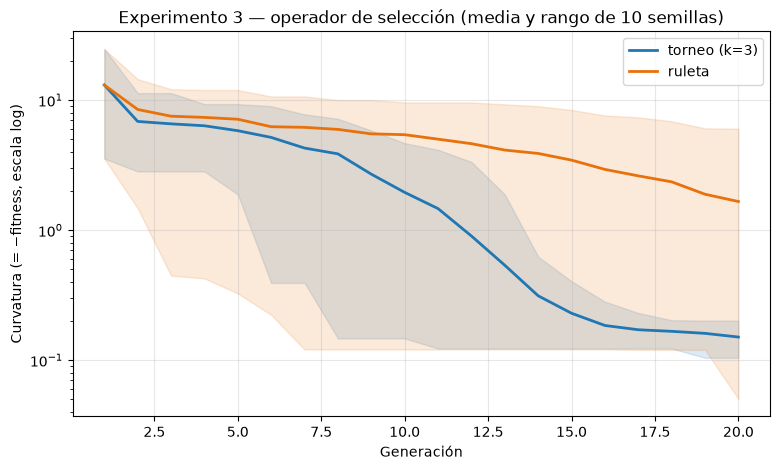

In [66]:
def correr_con(ga, **overrides):
    params = dict(population_size=100, lower_bound=-50, upper_bound=50,
                  generations=20, mutation_rate=1)
    params.update(overrides)

    curvas = []
    for s in SEEDS:
        random.seed(s)
        with contextlib.redirect_stdout(io.StringIO()):  
            _, bp, _ = ga(**params)
        curvas.append([fit for _, fit in bp])
    return curvas, [c[-1] for c in curvas]


with contextlib.redirect_stdout(io.StringIO()):
    random.seed(7); original = genetic_algorithm(20, -50, 50, 5, 1)[0]
random.seed(7); copia = genetic_algorithm_op(20, -50, 50, 5, 1, selection_fn=selection)[0]
assert original == copia, "la versión parametrizada no reproduce al GA original"
print("control de fidelidad: OK\n")

tabla = PrettyTable()
tabla.field_names = ["operador", "fitness medio", "mediana", "mejor", "peor", "desv"]

resultados_3 = []
for nombre, ga in (("torneo (k=3)", genetic_algorithm), ("ruleta", genetic_algorithm_roulette)):
    curvas, finales = correr_con(ga)
    resultados_3.append((nombre, curvas))
    tabla.add_row([nombre,
                   f"{statistics.mean(finales):.4f}",
                   f"{statistics.median(finales):.4f}",
                   f"{max(finales):.4f}",
                   f"{min(finales):.4f}",
                   f"{statistics.pstdev(finales):.4f}"])
print(tabla)

# Par categórico fijo: azul / naranja, separables también en visión con deficiencia de color.
COLOR_OP = {"torneo (k=3)": "#1f77b4", "ruleta": "#e8710a"}

fig, ax = plt.subplots(figsize=(9, 5))
for nombre, curvas in resultados_3:
    m = np.array(curvas) * -1                               # curvatura = -fitness (siempre > 0)
    gens = range(1, m.shape[1] + 1)
    ax.plot(gens, m.mean(axis=0), color=COLOR_OP[nombre], lw=2, label=nombre)
    ax.fill_between(gens, m.min(axis=0), m.max(axis=0), color=COLOR_OP[nombre], alpha=0.15)
ax.set_yscale('log')
ax.set_xlabel('Generación')
ax.set_ylabel('Curvatura (= −fitness, escala log)')
ax.set_title('Experimento 3 — operador de selección (media y rango de 10 semillas)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

#### Control: la presión de selección

La comparación anterior dice *qué* operador anda mejor, no *por qué*. Para explicarlo hace falta una
magnitud comparable entre los dos. La que sirve es la **presión de selección**: cuántas copias del
mejor individuo deja la selección en la camada de padres.

Para el torneo esa cantidad tiene un valor exacto. El mejor individuo de la población gana cualquier
torneo en el que participe, así que gana con probabilidad `k/n` y como
la selección se repite `n` veces, el número esperado de copias es exactamente **`k`**. No depende
del tamaño de la población ni de los valores de fitness, solo del orden: `tournament_size` **es** la
presión de selección, expresada como un número de copias.

Para la ruleta no hay fórmula equivalente. Las copias esperadas valen
`n * peso_del_mejor / suma_de_pesos`, que depende por completo de cómo estén repartidos los fitness
en esa generación particular.

El control tiene entonces dos partes: barrer `tournament_size` para ver qué le hace la presión a
este problema, y después medir empíricamente la presión real de los dos operadores, generación por
generación.

In [ ]:
from functools import partial


def ga_torneo(k):
    """Devuelve un GA que selecciona por torneo de tamaño k.
    functools.partial fija un argumento de una función y devuelve otra función
    ya configurada, como el .bind() de JavaScript."""
    seleccion_k = partial(selection, tournament_size=k)
    return lambda **kw: genetic_algorithm_op(selection_fn=seleccion_k, **kw)


tabla = PrettyTable()
tabla.field_names = ["operador", "copias esperadas del mejor", "fitness medio", "mediana", "peor", "desv"]

for k in (2, 3, 5, 10):
    _, finales = correr_con(ga_torneo(k))
    tabla.add_row([f"torneo k={k}", f"{k} (exacto)",
                   f"{statistics.mean(finales):.4f}",
                   f"{statistics.median(finales):.4f}",
                   f"{min(finales):.4f}",
                   f"{statistics.pstdev(finales):.4f}"])

_, finales_r = correr_con(genetic_algorithm_roulette)
tabla.add_row(["ruleta", "variable",
               f"{statistics.mean(finales_r):.4f}",
               f"{statistics.median(finales_r):.4f}",
               f"{min(finales_r):.4f}",
               f"{statistics.pstdev(finales_r):.4f}"])
print(tabla)

+-------------+----------------------------+---------------+---------+---------+--------+
|   operador  | copias esperadas del mejor | fitness medio | mediana |   peor  |  desv  |
+-------------+----------------------------+---------------+---------+---------+--------+
|  torneo k=2 |         2 (exacto)         |    -0.3053    | -0.2819 | -0.7304 | 0.2056 |
|  torneo k=3 |         3 (exacto)         |    -0.1506    | -0.1481 | -0.2013 | 0.0354 |
|  torneo k=6 |         6 (exacto)         |    -0.0928    | -0.0906 | -0.1702 | 0.0409 |
| torneo k=10 |        10 (exacto)         |    -0.0581    | -0.0535 | -0.1163 | 0.0341 |
|    ruleta   |          variable          |    -1.6594    | -0.4043 | -6.0323 | 2.1000 |
+-------------+----------------------------+---------------+---------+---------+--------+


copias esperadas del mejor individuo bajo torneo (la teoría dice exactamente k):
   k = 2   medido = 2.00
   k = 3   medido = 2.98
   k = 5   medido = 5.14
   k = 10  medido = 9.96

operador        presión media   rango (200 mediciones)   padres distintos
torneo (k=3)             3.00             [2.53, 3.63]               49.5
ruleta                   3.04            [1.22, 20.27]               59.3

ruleta, semilla por semilla (ordenado por presión media):
   semilla  8   presión media  2.01   ->   fitness final  -6.0323
   semilla  7   presión media  2.09   ->   fitness final  -4.5343
   semilla  9   presión media  2.39   ->   fitness final  -3.5524
   semilla  4   presión media  2.64   ->   fitness final  -0.6732
   semilla 10   presión media  2.73   ->   fitness final  -1.2436
   semilla  6   presión media  3.15   ->   fitness final  -0.1200
   semilla  1   presión media  3.22   ->   fitness final  -0.1354
   semilla  5   presión media  3.31   ->   fitness final  -0.0503
   semill

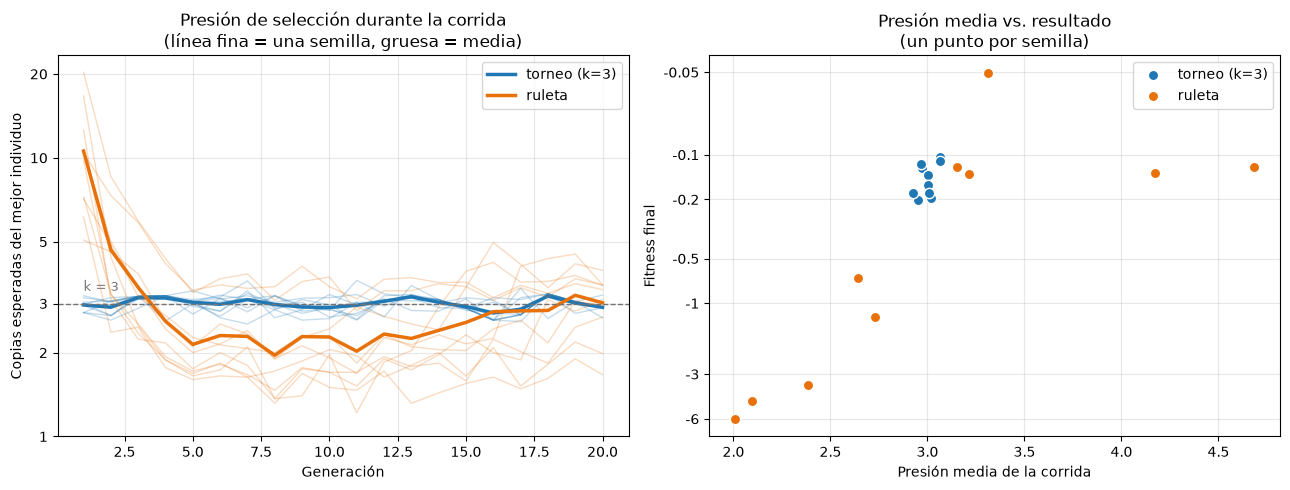

In [68]:
from matplotlib.ticker import FuncFormatter

numero = FuncFormatter(lambda v, _: f"{v:g}")      # etiquetas legibles en ejes logarítmicos


def presion_de_seleccion(population, fitnesses, selection_fn, reps=60):
    """Mide dos cosas del operador, promediando `reps` aplicaciones sobre la misma población:
      - copias esperadas del mejor individuo   -> la presión de selección
      - cantidad de padres distintos que pasan -> la diversidad que el operador deja pasar"""
    mejor = max(population, key=fitness_function)
    copias = distintos = 0
    for _ in range(reps):
        elegidos = selection_fn(population, fitnesses)
        copias += sum(1 for ind in elegidos if ind is mejor)
        distintos += len({id(ind) for ind in elegidos})
    return copias / reps, distintos / reps


# 1) Verificación empírica de la fórmula: bajo torneo, las copias esperadas del mejor valen k.
random.seed(7)
pob_test = create_initial_population(100, -50, 50)
fits_test = [fitness_function(ind) for ind in pob_test]
print("copias esperadas del mejor individuo bajo torneo (la teoría dice exactamente k):")
for k in (2, 3, 5, 10):
    medido, _ = presion_de_seleccion(pob_test, fits_test,
                                     partial(selection, tournament_size=k), reps=200)
    print(f"   k = {k:<3} medido = {medido:.2f}")

# 2) Presión real de los dos operadores, generación por generación y semilla por semilla.
presiones, diversidades, finales_op = {}, {}, {}
for nombre, sel_fn, ga in (("torneo (k=3)", selection, genetic_algorithm),
                           ("ruleta", selection_roulette, genetic_algorithm_roulette)):
    curvas_p, curvas_d, fins = [], [], []
    for s in SEEDS:
        random.seed(s)
        with contextlib.redirect_stdout(io.StringIO()):
            _, bp, pops = ga(100, -50, 50, 20, 1)
        serie_p, serie_d = [], []
        for g, pop in enumerate(pops):
            fits = [fitness_function(ind) for ind in pop]
            random.seed(50_000 + g)            # misma secuencia aleatoria para los dos operadores
            p, d = presion_de_seleccion(pop, fits, sel_fn)
            serie_p.append(p); serie_d.append(d)
        curvas_p.append(serie_p); curvas_d.append(serie_d); fins.append(bp[-1][1])
    presiones[nombre] = np.array(curvas_p)
    diversidades[nombre] = np.array(curvas_d)
    finales_op[nombre] = fins

print(f"\n{'operador':14s} {'presión media':>14s} {'rango (200 mediciones)':>24s} {'padres distintos':>18s}")
for nombre, m in presiones.items():
    print(f"{nombre:14s} {m.mean():>14.2f} {f'[{m.min():.2f}, {m.max():.2f}]':>24s} "
          f"{diversidades[nombre].mean():>18.1f}")

print("\nruleta, semilla por semilla (ordenado por presión media):")
for p, f, s in sorted(zip(presiones["ruleta"].mean(axis=1), finales_op["ruleta"], SEEDS)):
    print(f"   semilla {s:>2}   presión media {p:5.2f}   ->   fitness final {f:8.4f}")

rho = statistics.correlation(presiones["ruleta"].mean(axis=1).tolist(),
                             finales_op["ruleta"], method="ranked")
print(f"\ncorrelación de rangos (Spearman) entre presión media y fitness final: {rho:.2f}")

# 3) Gráficos.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for nombre, m in presiones.items():
    gens = range(1, m.shape[1] + 1)
    for fila in m:                                     # una línea fina por semilla
        ax1.plot(gens, fila, color=COLOR_OP[nombre], alpha=0.25, lw=1)
    ax1.plot(gens, m.mean(axis=0), color=COLOR_OP[nombre], lw=2.5, label=nombre)
ax1.axhline(3, color='0.45', ls='--', lw=1)
ax1.text(1, 3.25, 'k = 3', ha='left', va='bottom', color='0.45', fontsize=9)
ax1.set_yscale('log')
ax1.set_yticks([1, 2, 3, 5, 10, 20]); ax1.minorticks_off()
ax1.yaxis.set_major_formatter(numero)
ax1.set_xlabel('Generación')
ax1.set_ylabel('Copias esperadas del mejor individuo')
ax1.set_title('Presión de selección durante la corrida\n(línea fina = una semilla, gruesa = media)')
ax1.legend(); ax1.grid(alpha=0.3)

for nombre, m in presiones.items():
    ax2.scatter(m.mean(axis=1), finales_op[nombre], color=COLOR_OP[nombre], s=55,
                edgecolor='white', linewidth=1, label=nombre, zorder=3)
ax2.set_yscale('symlog', linthresh=0.1)
ax2.set_yticks([-6, -3, -1, -0.5, -0.2, -0.1, -0.05]); ax2.minorticks_off()
ax2.yaxis.set_major_formatter(numero)
ax2.set_xlabel('Presión media de la corrida')
ax2.set_ylabel('Fitness final')
ax2.set_title('Presión media vs. resultado\n(un punto por semilla)')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

**Análisis del Experimento 3**

Reemplazar el torneo por la ruleta **empeora el resultado medio en un orden de magnitud**: el
fitness final promedio pasa de **−0.1506** a **−1.6594**. Pero quedarse con la media induce a error,
porque la mediana de la ruleta es −0.4043 y su **mejor** corrida (−0.0503) es mejor que la mejor del
torneo (−0.1042). La ruleta no es un operador peor: es un operador **inconsistente**. El desvío lo
dice sin ambigüedad: **2.1000 contra 0.0354**, casi sesenta veces más dispersión. Cinco de las diez
semillas terminan entre −0.135 y −0.050, a la altura del torneo o mejor, y las otras cinco entre
−0.673 y −6.032.

La explicación natural de esa inconsistencia sería la convergencia prematura: la ruleta amplifica
demasiado al mejor individuo, la población pierde diversidad y el algoritmo se queda clavado. **Los
datos no la sostienen.** El diagnóstico mide cuántos padres *distintos* deja pasar cada operador, y
la ruleta deja **59.3** contra **49.5** del torneo: conserva *más* diversidad, no menos.

Lo que sí explica el resultado es la **presión de selección**, medida como el número esperado de
copias del mejor individuo que la selección deposita en la camada de padres. Para el torneo esa
cantidad tiene un valor exacto y deducible: el mejor individuo gana cualquier torneo en el que
participe, entra en la muestra con probabilidad `k/n`, y como la selección se repite `n` veces, el
valor esperado es exactamente **`k`**, sin depender del tamaño de la población ni de los valores de
fitness. La medición empírica lo confirma: 2.00, 2.98, 5.14 y 9.96 copias para `k` igual a 2, 3, 5 y
10. En otras palabras, **`tournament_size` *es* la presión de selección**, expresada directamente
como un número de copias.

Sobre las 200 mediciones del experimento (10 semillas × 20 generaciones), la presión del torneo se
mantuvo en el rango **[2.53, 3.63]**, siempre alrededor de 3; la dispersión que se ve es ruido de
medición, no deriva. La ruleta, en promedio global, tiene prácticamente **la misma** presión:
**3.04**. Pero su rango sobre las mismas 200 mediciones es **[1.22, 20.27]**. La presión de la
ruleta no es un parámetro que el programador elija, sino una consecuencia emergente de cómo estén
repartidos los fitness en esa generación particular, y se mueve de forma impredecible a lo largo de
la corrida: arranca cerca de 11 copias en la primera generación, cuando los fitness difieren en
órdenes de magnitud, y cae a poco más de 2 una vez que la población se homogeneiza.

Ahí está el daño, y la comparación entre semillas lo confirma: la correlación de rangos (Spearman)
entre la presión media de cada corrida y su fitness final es **ρ = 0.85**. Las cinco semillas cuya
presión media superó 3.1 terminaron todas entre −0.135 y −0.050; las cinco que quedaron por debajo
de 2.75 terminaron todas entre −0.673 y −6.032. No hay un solo caso cruzado. El panel derecho del
gráfico lo muestra como una nube ordenada para la ruleta y un único punto apretado para el torneo.

El barrido de `tournament_size` cierra el argumento mostrando que este problema **premia la presión
alta**: −0.3053 con `k`=2, −0.1506 con `k`=3, −0.1330 con `k`=5 y **−0.0581 con `k`=10**, una mejora
monótona. Es coherente con lo que ya se sabía del paisaje de búsqueda: el óptimo está en el borde
`a → 0⁺` y solo se alcanza de forma asintótica, caminando con pasos de mutación de ±1, de modo que
lo que el algoritmo necesita es explotar agresivamente al mejor individuo en cada generación. La
ruleta no puede garantizar eso, porque su presión no es una decisión de diseño sino un emergente del
paisaje.

La conclusión práctica es que **el torneo conviene no por ser más selectivo, sino por ser
predecible**. Su presión es un número que se elige y que no cambia aunque el fitness se mueva varios
órdenes de magnitud entre la primera generación y la última. La ruleta, además, obliga a tomar una
decisión que no forma parte de la definición del operador —cómo transformar un fitness negativo en
un peso no negativo— y de la que los resultados dependen. Un operador cuyo comportamiento efectivo
queda determinado por una elección de implementación no documentada es justamente lo que no se
quiere en un algoritmo de optimización.